# Predicting Future Life Expectancy
#### _(All Project Code and Non-Annotated)_

### Group Members
- Huy Dao
- Aaron Watkins
- Jeanne du Fay de Lavallaz
- Harrison Gill

## Project Motivation

Life expectancy is one of the most widely used indicators of national health and development, reflecting the combined effects of healthcare access, economic conditions, lifestyle factors, and public policy. While most existing analyses focus on explaining current or historical life expectancy, our research focusses on long-term prediction by estimating life expectancy ten years in the future.

This forward-looking perspective is valuable because many interventions, such as improving education or addressing chronic disease, take years to produce measurable effects. Our work to identify which factors most strongly influence future outcomes could help policymakers or global health organizations prioritize investments that yield the greatest long-term impact.

## Project Goal

Our objective is to train machine learning models that leverage large-scale, multi-dimensional data that includes health indicators, economic metrics, and demographic data to predict national life expectancy a decade ahead. This problem is well-suited for Big Data Analytics because we need to (1) handle missing and inconsistent data so that we can then (2) analyze the relationships between these variables that are complex and difficult to understand with qualitiative or traditional analytical methods.

## Project Deliverable
This document is a consolidated and annotated version of our full Notebook that includes additional exploratory analysis, modeling approaches, and visualizations, and evaluations.

Each of the sections listed in the _Table of Contents_ have an introduction at the start and then a description of the findings at the end. Throughout, we describe our analysis, interpret key visualizations, and identify key takeaways from the results.


## Table of Contents
_Note that links may not functional after downloading._
1. [Data Overview](#i.-data-overview)
2. [Data Preprocessing](#ii.-data-preprocessing)
3. [Exploratory Data Analysis](#iii.-exploratory-data-analysis)
4. [Modeling & Evaluation](#iv.-model-and-evaluation)
5. [Conclusion](#v.-conclusion)


In [95]:
from google.colab import drive
drive_path = '/content/drive'
drive.mount(drive_path, force_remount=True)

Mounted at /content/drive


In [96]:
# Basic set up - libraries and utilities
# Basic libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# ML utilities
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

sns.set_style("whitegrid")

# import modules
import sys
import os


# I. Data Overview

In [97]:
# Load File
# Everyone needs to upload the csv file to their own MyDrive
df = pd.read_csv('/content/drive/MyDrive/data.csv')


**Basic Exploratory Data Analysis**



In [98]:
print("====================================")
print("DATASET OVERVIEW")
print("====================================")

print("\nShape of dataset:")
print(f'Dimension: {df.shape}')

# print("\n====================================")
# print("DATASET STRUCTURE")
# print("====================================")
print("\nInfo:")
df.info()

DATASET OVERVIEW

Shape of dataset:
Dimension: (89010, 61)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89010 entries, 0 to 89009
Data columns (total 61 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    89010 non-null  object 
 1   Country Code    89010 non-null  object 
 2   Indicator Name  89010 non-null  object 
 3   Indicator Code  89010 non-null  object 
 4   1960            35482 non-null  float64
 5   1961            35325 non-null  float64
 6   1962            35889 non-null  float64
 7   1963            35452 non-null  float64
 8   1964            35483 non-null  float64
 9   1965            35603 non-null  float64
 10  1966            35538 non-null  float64
 11  1967            36022 non-null  float64
 12  1968            35577 non-null  float64
 13  1969            35630 non-null  float64
 14  1970            36910 non-null  float64
 15  1971            37578 non-null  float64
 16  1972      

In [99]:
print("\nSummary statistics:")
df.describe()


Summary statistics:


,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,Unnamed: 60
count,3.548200e+04,3.532500e+04,3.588900e+04,3.545200e+04,3.548300e+04,3.560300e+04,3.553800e+04,3.602200e+04,3.557700e+04,3.563000e+04,...,5.425500e+04,5.387800e+04,5.443700e+04,5.709900e+04,5.492200e+04,5.492700e+04,5.292400e+04,5.219900e+04,4.306800e+04,0.0
mean,4.398856e+06,4.477329e+06,4.483279e+06,4.634875e+06,4.727806e+06,4.810557e+06,4.923225e+06,4.958680e+06,5.126162e+06,5.229267e+06,...,1.066701e+08,1.178440e+08,1.194416e+08,1.202183e+08,1.354606e+08,1.381746e+08,1.470674e+08,1.534580e+08,9.105685e+06,NaN
std,4.948245e+07,5.013205e+07,5.054473e+07,5.192122e+07,5.297849e+07,5.401988e+07,5.526006e+07,5.607026e+07,5.763263e+07,5.887277e+07,...,1.017662e+10,1.077350e+10,1.114136e+10,1.132855e+10,1.212198e+10,1.255757e+10,1.312843e+10,1.388442e+10,1.112609e+08,NaN
min,-2.374024e+00,-2.498824e+00,-3.826648e+06,-3.206682e+00,-3.078607e+00,-2.978527e+00,-3.072258e+00,-4.094255e+06,-4.263603e+00,-4.645452e+00,...,-2.272986e+07,-7.720454e+00,-7.829848e+00,-9.816607e+00,-8.166639e+00,-1.578482e+07,-7.726345e+00,-7.709485e+00,-7.784170e+00,NaN
25%,1.907975e+01,2.130000e+01,1.790000e+01,2.228200e+01,2.236877e+01,2.013357e+01,2.196439e+01,1.779723e+01,2.226600e+01,2.237234e+01,...,1.360000e+01,1.351170e+01,1.377504e+01,1.326888e+01,1.410000e+01,1.257937e+01,1.393631e+01,1.387011e+01,1.490000e+01,NaN
50%,5.282000e+03,5.794000e+03,5.158000e+03,5.945000e+03,6.065000e+03,5.998000e+03,6.240000e+03,5.767000e+03,6.438000e+03,6.529500e+03,...,9.608101e+01,9.699493e+01,9.670839e+01,9.155791e+01,9.633862e+01,9.610010e+01,9.900000e+01,9.896778e+01,2.206000e+03,NaN
75%,9.993525e+04,1.034000e+05,1.025840e+05,1.078488e+05,1.107500e+05,1.125765e+05,1.156312e+05,1.151888e+05,1.211970e+05,1.243615e+05,...,8.397350e+04,8.621775e+04,8.342100e+04,6.758400e+04,8.207750e+04,8.399800e+04,9.839350e+04,1.037375e+05,1.802958e+05,NaN
max,3.035056e+09,3.076121e+09,3.129064e+09,3.193947e+09,3.259355e+09,3.326054e+09,3.395866e+09,3.465297e+09,3.535512e+09,3.609910e+09,...,2.253595e+12,2.358301e+12,2.451062e+12,2.546451e+12,2.646913e+12,2.750543e+12,2.833419e+12,2.985748e+12,7.346633e+09,NaN


In [100]:
# df['Indicator Name'].unique()

In [101]:
print("\nPreview of dataset:")
df.head()


Preview of dataset:


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,Unnamed: 60
0,Arab World,ARB,% of females ages 15-49 having comprehensive c...,SH.HIV.KNOW.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,% of males ages 15-49 having comprehensive cor...,SH.HIV.KNOW.MA.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,133.555013,134.159119,134.857912,134.504576,134.105211,133.569626,...,49.999851,49.887046,49.781207,49.672975,49.536047,49.383745,48.796558,48.196418,NaN,NaN
3,Arab World,ARB,Adults (ages 15+) and children (0-14 years) li...,SH.HIV.TOTL,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,Adults (ages 15+) and children (ages 0-14) new...,SH.HIV.INCD.TL,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [102]:
print("\nRandom sample:")
df.sample(5)


Random sample:


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,Unnamed: 60
61446,Nauru,NRU,"Age population, age 12, female, interpolated",SP.POP.AG12.FE.IN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12587,Sub-Saharan Africa,SSF,Male population 45-49,SP.POP.4549.MA,4321315.0,4405432.0,4500658.0,4604618.0,4713927.0,4826299.0,...,13157073.0,13563799.0,13984371.0,14415228.0,14844155.0,15294926.0,15775843.0,16299271.0,16871842.0,NaN
14141,World,WLD,Use of Intermittent Preventive Treatment of ma...,SH.MLR.SPF2.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63403,Nicaragua,NIC,Postnatal care coverage (% mothers),SH.STA.PNVC.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
70594,San Marino,SMR,"Population ages 00-14, male (% of total)",SP.POP.0014.MA.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [103]:
print("\n====================================")
print("COUNTRIES")
print("====================================")

n_countries = df["Country Name"].nunique()
print("Number of countries:", n_countries)

print("\nExample countries:")
print(df["Country Name"].unique()[:20])



COUNTRIES
Number of countries: 258

Example countries:
['Arab World' 'Caribbean small states' 'Central Europe and the Baltics'
 'Early-demographic dividend' 'East Asia & Pacific'
 'East Asia & Pacific (excluding high income)'
 'East Asia & Pacific (IDA & IBRD countries)' 'Euro area'
 'Europe & Central Asia' 'Europe & Central Asia (excluding high income)'
 'Europe & Central Asia (IDA & IBRD countries)' 'European Union'
 'Fragile and conflict affected situations'
 'Heavily indebted poor countries (HIPC)' 'High income'
 'Late-demographic dividend' 'Latin America & Caribbean'
 'Latin America & Caribbean (excluding high income)'
 'Latin America & the Caribbean (IDA & IBRD countries)'
 'Least developed countries: UN classification']


In [104]:
print("\n====================================")
print("INDICATORS")
print("====================================")

n_indicators = df["Indicator Name"].nunique()
print("Number of indicators:", n_indicators)

print("\nMost common indicators:")
print(df["Indicator Name"].value_counts().head(20))


INDICATORS
Number of indicators: 345

Most common indicators:
Indicator Name
Women's share of population ages 15+ living with HIV (%)                                                                 258
% of females ages 15-49 having comprehensive correct knowledge about HIV (2 prevent ways and reject 3 misconceptions)    258
% of males ages 15-49 having comprehensive correct knowledge about HIV (2 prevent ways and reject 3 misconceptions)      258
Adolescent fertility rate (births per 1,000 women ages 15-19)                                                            258
Adults (ages 15+) and children (0-14 years) living with HIV                                                              258
Adults (ages 15+) and children (ages 0-14) newly infected with HIV                                                       258
Adults (ages 15+) living with HIV                                                                                        258
Adults (ages 15+) newly infected with HIV      

In [105]:
print("\n====================================")
print("YEAR COLUMNS")
print("====================================")

year_cols = [c for c in df.columns if c.isdigit()]

print("Number of year columns:", len(year_cols))
print("First years:", year_cols[:5])
print("Last years:", year_cols[-5:])


YEAR COLUMNS
Number of year columns: 56
First years: ['1960', '1961', '1962', '1963', '1964']
Last years: ['2011', '2012', '2013', '2014', '2015']


In [106]:
print("\n====================================")
print("MISSING DATA")
print("====================================")

missing = df.isna().sum().sort_values(ascending=False)
print("\nTop columns with missing values:")
print(missing.sample(5))

missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
print("\nMissing percentage:")
print(missing_percent.sample(5))



MISSING DATA

Top columns with missing values:
2006    34612
1999    36568
2014    36811
2000    32338
2004    35593
dtype: int64

Missing percentage:
2015    51.614425
2006    38.885518
1989    55.867880
2014    41.356027
1962    59.679811
dtype: float64


In [107]:
print("\n====================================")
print("SEARCH EXAMPLES")
print("====================================")

print("\nIndicators related to HIV:")
print(df[df["Indicator Name"].str.contains("HIV", case=False, na=False)]["Indicator Name"].unique())

print("\nIndicators related to immunization:")
print(df[df["Indicator Name"].str.contains("immun", case=False, na=False)]["Indicator Name"].unique())



SEARCH EXAMPLES

Indicators related to HIV:
['% of females ages 15-49 having comprehensive correct knowledge about HIV (2 prevent ways and reject 3 misconceptions)'
 '% of males ages 15-49 having comprehensive correct knowledge about HIV (2 prevent ways and reject 3 misconceptions)'
 'Adults (ages 15+) and children (0-14 years) living with HIV'
 'Adults (ages 15+) and children (ages 0-14) newly infected with HIV'
 'Adults (ages 15+) living with HIV'
 'Adults (ages 15+) newly infected with HIV'
 'Antiretroviral therapy coverage (% of people living with HIV)'
 'Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV)'
 'Children (0-14) living with HIV'
 'Children (ages 0-14) newly infected with HIV'
 'Children orphaned by HIV/AIDS'
 'Comprehensive correct knowledge of HIV/AIDS, ages 15-24, female (2 prevent ways and reject 3 misconceptions)'
 'Comprehensive correct knowledge of HIV/AIDS, ages 15-24, male (2 prevent ways and reject 3 misconceptions)'
 'Incidence of

In [108]:
fert_rate_df = df[df['Indicator Name']=='Fertility rate, total (births per woman)']
print(fert_rate_df.shape)
fert_rate_df.head()

(258, 61)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,Unnamed: 60
117,Arab World,ARB,"Fertility rate, total (births per woman)",SP.DYN.TFRT.IN,6.924376,6.946426,6.964454,6.975892,6.978893,6.972297,...,3.443135,3.437033,3.435201,3.437177,3.434191,3.425141,3.405207,3.374973,NaN,NaN
462,Caribbean small states,CSS,"Fertility rate, total (births per woman)",SP.DYN.TFRT.IN,5.520103,5.532579,5.523020,5.491322,5.438511,5.366734,...,2.228442,2.206880,2.184615,2.161358,2.138786,2.116920,2.096189,2.076811,NaN,NaN
807,Central Europe and the Baltics,CEB,"Fertility rate, total (births per woman)",SP.DYN.TFRT.IN,2.498917,2.402686,2.311378,2.316327,2.261526,2.201756,...,1.381133,1.466214,1.490283,1.465043,1.395964,1.415434,1.378132,1.377808,NaN,NaN
1152,Early-demographic dividend,EAR,"Fertility rate, total (births per woman)",SP.DYN.TFRT.IN,6.145565,6.144069,6.138306,6.127664,6.111425,6.089301,...,2.905960,2.858715,2.812477,2.767754,2.726427,2.687653,2.650710,2.614354,NaN,NaN
1497,East Asia & Pacific,EAS,"Fertility rate, total (births per woman)",SP.DYN.TFRT.IN,5.394305,5.471786,5.547543,5.623758,5.683514,5.723967,...,1.768328,1.769677,1.769315,1.773065,1.775423,1.779473,1.778317,1.780712,NaN,NaN


In [109]:
df_no_nas = df.dropna()
df_no_nas[df_no_nas['Indicator Name']=='Wanted fertility rate (births per woman)']

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,Unnamed: 60



EXAMPLE INDICATOR ANALYSIS

Country comparison example:


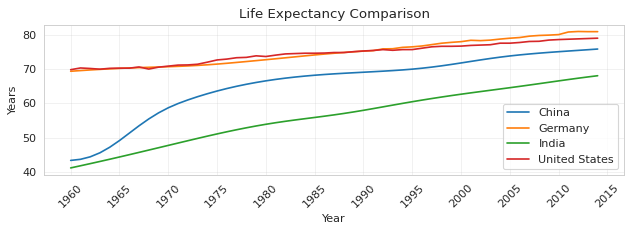

In [110]:
print("\n====================================")
print("EXAMPLE INDICATOR ANALYSIS")
print("====================================")

year_cols = sorted([col for col in df.columns if col.isdigit()], key=int)
year_vals = [int(y) for y in year_cols]

indicator = "Life expectancy at birth, total (years)"

if indicator in df["Indicator Name"].values:
    temp = df[df["Indicator Name"] == indicator]

    print("\nCountry comparison example:")

    countries = ["United States", "China", "India", "Germany"]
    subset = temp[temp["Country Name"].isin(countries)]

    plt.figure(figsize=(8, 3), dpi=80)

    for _, row in subset.iterrows():
        y = pd.to_numeric(row[year_cols], errors="coerce")
        plt.plot(year_vals, y, label=row["Country Name"])

    plt.legend()
    plt.title("Life Expectancy Comparison")
    plt.xlabel("Year")
    plt.ylabel("Years")

    # show fewer year labels
    plt.xticks(year_vals[::5], rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("Life expectancy indicator not found in dataset.")

# II. Data Preprocessing

To prepare the dataset for analysis and modeling, several preprocessing steps were applied to ensure data quality, consistency, and usability.

First, the dataset was cleaned using a custom function to standardize structure and isolate year-based columns. Rows with all missing values across time were removed from the dataset, while rows with even some partial data were retained just so that we could preserve as much information as possible.

Next, we evaluated missingness at the row level by calculating the number of missing values across all year columns. This allowed us to understand data completeness and make informed filtering decisions. Based on the distribution, we set a threshold to remove rows with excessive missing data, ensuring that retained observations contained sufficient historical information.

To address remaining gaps, we applied linear interpolation across the time dimension**. This method estimates missing values using surrounding data points, making it particularly appropriate for time-series data such as health indicators, where trends are generally continuous over time.

We also verified that:
- Duplicate rows were not present
- Missing values were successfully handled after filtering and imputation

Overall, these steps ensured that the dataset maintained a balance between data completeness and coverage, enabling more reliable downstream analysis and modeling.

In [111]:
modude_path = "/content/drive/MyDrive"

sys.path.append(modude_path)

print(os.path.exists(os.path.join(modude_path, "data_utils.py")))

from data_utils import clean_health_data


True


In [112]:
# Clean df
df_clean, year_cols = clean_health_data(df)
df_clean.reset_index(drop=True, inplace=True)

print(f'Cleaned DF shape: {df_clean.shape}')
df_clean.head()


Cleaned DF shape: (68000, 60)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
0,Arab World,ARB,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,133.555013,134.159119,134.857912,134.504576,134.105211,133.569626,...,50.329135,49.999851,49.887046,49.781207,49.672975,49.536047,49.383745,48.796558,48.196418,NaN
1,Arab World,ARB,Age dependency ratio (% of working-age populat...,SP.POP.DPND,87.799235,89.221714,90.502403,91.603014,92.414916,92.868163,...,65.786728,64.630067,63.602627,62.738022,62.053505,61.794943,61.681904,61.678686,61.719792,61.754194
2,Arab World,ARB,"Age dependency ratio, old",SP.POP.DPND.OL,6.635328,6.746978,6.840980,6.915871,6.968155,6.996499,...,6.821022,6.765206,6.712015,6.672599,6.653749,6.678820,6.715494,6.767541,6.840458,6.937488
3,Arab World,ARB,"Age dependency ratio, young",SP.POP.DPND.YG,81.024250,82.316142,83.459807,84.413972,85.096657,85.470717,...,57.359235,56.168572,55.123404,54.255968,53.578642,53.318234,53.209074,53.205356,53.228309,53.218107
4,Arab World,ARB,Antiretroviral therapy coverage (% of people l...,SH.HIV.ARTC.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.914425,3.958723,5.709145,7.360087,8.827443,10.179933,11.921734,14.094578,16.561200,19.868578


In [113]:
# Check duplicate rows
dup_count = df_clean.duplicated().sum()
print("Duplicate rows:", dup_count)

# Total missing values
print("Total missing values:", df_clean.isnull().sum().sum())


Duplicate rows: 0
Total missing values: 1331958


- We only removed the rows with ALL years were missing. We still keep the rows with SOME missing values
- In "df_clean.isnull().sum().sum()" we caculate the toteal missing values per year, then we add them together for the entire data set.


In [114]:
# Check the number missing values per row
nan_per_row = df_clean[year_cols].isnull().sum(axis=1)
print("Least NaNs in a row:", nan_per_row.min())
print("Most NaNs in a row:", nan_per_row.max())
nan_per_row.describe()

Least NaNs in a row: 0
Most NaNs in a row: 55


,0
count,68000.000000
mean,19.587618
std,21.974664
min,0.000000
25%,0.000000
50%,1.000000
75%,39.000000
max,55.000000


Interpretation:
- 25% of rows have 0 missing values (complete)
- 50% of rows have ≤ 1 missing value (almost complete)
- 75% of rows have ≤ 39 missing values




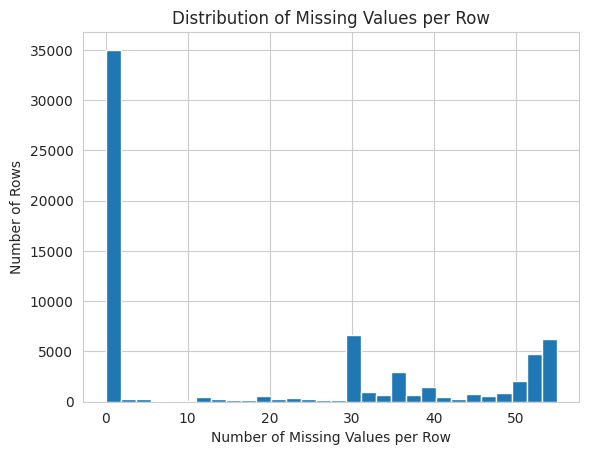

In [115]:
# Plot the distribution of Missing Values per Row
plt.hist(nan_per_row, bins=30)
plt.xlabel("Number of Missing Values per Row")
plt.ylabel("Number of Rows")
plt.title("Distribution of Missing Values per Row")
plt.show()

Based on the plot, my threshold will be 50 which means:

*   If nan_count < 50  → keep ≥7 observed years and later impute missing values
*   If nan_count ≥ 50  → drop < 6 observed years



In [116]:
#  Adding helper column and choosing threshold
df_clean["nan_count"] = nan_per_row
threshold = 50


In [117]:
# Check if we drop important data before dropping
df_clean[df_clean["nan_count"] >= threshold]["Indicator Name"].value_counts().head(10)

,count
Indicator Name,
Diabetes prevalence (% of population ages 20 to 79),249
"Mortality rate, infant, female (per 1,000 live births)",234
"Mortality rate, under-5, female (per 1,000)",234
"Mortality rate, under-5, male (per 1,000)",234
"Mortality rate, infant, male (per 1,000 live births)",234
Risk of impoverishing expenditure for surgical care (% of people at risk),227
Risk of catastrophic expenditure for surgical care (% of people at risk),227
"Number of surgical procedures (per 100,000 population)",225
"Mortality caused by road traffic injury (per 100,000 people)",220


In [118]:
# Drop and display the comparison
df_filtered = df_clean[df_clean["nan_count"] < threshold]
print("Rows before filtering:", df_clean.shape[0])
print("Rows after filtering:", df_filtered.shape[0])

removed_rows = df_clean.shape[0] - df_filtered.shape[0]
print("Rows removed:", removed_rows)

Rows before filtering: 68000
Rows after filtering: 54959
Rows removed: 13041


In [119]:
# Drop helper column
df_filtered = df_filtered.drop(columns="nan_count")


In [120]:
# Impute missing values for kept observations
df_filtered[year_cols] = df_filtered[year_cols].interpolate(axis=1)

# Fill edge gaps (1960 and 2015)
df_filtered[year_cols] = (df_filtered[year_cols].interpolate(axis=1)
                                                .ffill(axis=1)
                                                .bfill(axis=1)
                         )


We applied *linear interpolation* across the time dimension because we estimates missing values by using the surrounding observed values in adjacent years. It reflects the change gradually over time rather than abruptly which fits to time series scenario.

Reason for not choosing other methods:
*   *Mean or median imputation* would ignore the temporal structure of the data and could distort long-term trends.
*   *Forward / backward fill* may propagate outdated values across long time gaps.



In [121]:
# Verified handling all Null values
nan_per_row_after = df_filtered[year_cols].isnull().sum(axis=1)
print("NaNs in a row:", nan_per_row_after)

NaNs in a row: 0        0
1        0
2        0
3        0
4        0
        ..
67990    0
67991    0
67992    0
67997    0
67999    0
Length: 54959, dtype: int64


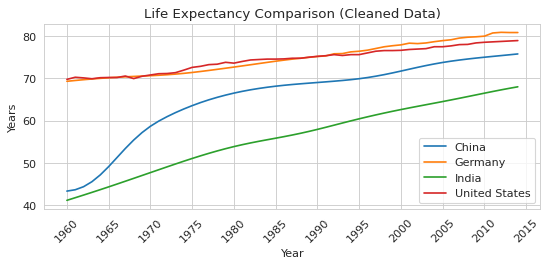

In [122]:
# Plot Life Expectancy Comparison (cleaned data)
subset = temp[temp["Country Name"].isin(countries)]

plt.figure(figsize=(8, 3), dpi=80)

for _, row in subset.iterrows():
    plt.plot(year_cols, row[year_cols], label=row["Country Name"])

plt.legend()

plt.title("Life Expectancy Comparison (Cleaned Data)")
plt.xlabel("Year")
plt.ylabel("Years")

plt.xticks(year_cols[::5], rotation=45)

plt.show()

Notice the trends haven't changed after the handling missing values.

# III. Exploratory Data Analysis (EDA)

In the exploratory analysis we focused on understanding the structure, distribution, and relationships within the dataset, most particularly across countries, indicators, and time.

Initial obvservations revealed a wide-format dataset where each row represents a country-indicator pair and each column represents a year. To enable deeper analysis, the data was reshaped into a long format, allowing time-series trends and cross-country comparisons to be analyzed more effectively.

Key observations from the analysis include:

- **Data Completeness:** A large portion of the dataset contained minimal missing values after preprocessing, which gave us confidence that we could perform reliable trend analysis.
- **Temporal Trends:** Health indicators such as life expectancy exhibited generally smooth, increasing trends over time across most countries, supporting the validity of interpolation methods used earlier.
- **Distribution of Target Variable:** The distribution of life expectancy values showed a reasonable spread across countries, with no extreme anomalies, making it suitable for predictive modeling.
- **Feature Relationships:** By restructuring the data into a modeling-friendly format (one row per country-year), we enabled analysis of how different indicators relate to future outcomes, such as life expectancy.

Additionally, a 10-year-ahead prediction target was constructed to support forward-looking modeling. This transformation allows the analysis to move beyond descriptive insights and into predictive understanding.

Overall, the EDA confirmed that the dataset is well-structured for modeling and that the underlying trends are consistent and interpretable across both time and geography.

# ============================================================
# Further EDA
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
RANDOM_STATE = 42




In [123]:
# -----------------------------
# Helper functions
# -----------------------------
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def evaluate_model(model_name, y_true, y_pred, n_features=None):
    return {
        "Model": model_name,
        "Num Features / Components": n_features,
        "RMSE": rmse(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }


In [124]:

# -----------------------------
# Reshape to long format
# -----------------------------
# Current format:
# one row = one country-indicator, with years as columns
# We convert to:
# one row = one country-year-indicator value

id_cols = ["Country Name", "Country Code", "Indicator Name", "Indicator Code"]

long_df = df_filtered.melt(
    id_vars=id_cols,
    value_vars=year_cols,
    var_name="Year",
    value_name="Value"
)

long_df["Year"] = long_df["Year"].astype(int)

print("Long-format dataframe shape:", long_df.shape)
long_df.head()


Long-format dataframe shape: (3077704, 6)


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
0,Arab World,ARB,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,1960,133.555013
1,Arab World,ARB,Age dependency ratio (% of working-age populat...,SP.POP.DPND,1960,87.799235
2,Arab World,ARB,"Age dependency ratio, old",SP.POP.DPND.OL,1960,6.635328
3,Arab World,ARB,"Age dependency ratio, young",SP.POP.DPND.YG,1960,81.024250
4,Arab World,ARB,Antiretroviral therapy coverage (% of people l...,SH.HIV.ARTC.ZS,1960,0.024814


In [125]:
# -----------------------------
# Pivot to modeling table
# -----------------------------
# Goal:
# one row = one country-year
# columns = health indicators
# target = life expectancy 10 years later

wide_df = long_df.pivot_table(
    index=["Country Name", "Country Code", "Year"],
    columns="Indicator Name",
    values="Value",
    aggfunc="mean"
).reset_index()

wide_df.columns.name = None

print("Wide modeling dataframe shape:", wide_df.shape)
wide_df.head()


Wide modeling dataframe shape: (14448, 315)


,Country Name,Country Code,Year,AIDS estimated deaths (UNAIDS estimates),ARI treatment (% of children under 5 taken to a health provider),"Adolescent fertility rate (births per 1,000 women ages 15-19)",Adults (ages 15+) and children (0-14 years) living with HIV,Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Adults (ages 15+) living with HIV,Adults (ages 15+) newly infected with HIV,...,"Unemployment, total (% of total labor force)",Unmet need for contraception (% of married women ages 15-49),Urban population,Urban population (% of total),Urban population growth (annual %),Urban poverty headcount ratio at national poverty lines (% of urban population),Use of insecticide-treated bed nets (% of under-5 population),Vitamin A supplementation coverage rate (% of children ages 6-59 months),Wanted fertility rate (births per woman),Women's share of population ages 15+ living with HIV (%)
0,Afghanistan,AFG,1960,100.0,NaN,145.321,500.0,100.0,500.0,100.0,...,8.6,NaN,739462.0,8.221,5.253807,NaN,NaN,78.0,NaN,23.098592
1,Afghanistan,AFG,1961,100.0,NaN,145.321,500.0,100.0,500.0,100.0,...,8.6,NaN,779754.0,8.508,5.305559,NaN,NaN,78.0,NaN,23.098592
2,Afghanistan,AFG,1962,100.0,NaN,145.321,500.0,100.0,500.0,100.0,...,8.6,NaN,822719.0,8.805,5.363622,NaN,NaN,78.0,NaN,23.098592
3,Afghanistan,AFG,1963,100.0,NaN,145.321,500.0,100.0,500.0,100.0,...,8.6,NaN,868325.0,9.110,5.395136,NaN,NaN,78.0,NaN,23.098592
4,Afghanistan,AFG,1964,100.0,NaN,145.321,500.0,100.0,500.0,100.0,...,8.6,NaN,917022.0,9.426,5.456539,NaN,NaN,78.0,NaN,23.098592


In [126]:
# -----------------------------
# Create 10-year-ahead target
# -----------------------------
life_col = "Life expectancy at birth, total (years)"

if life_col not in wide_df.columns:
    raise ValueError(f"'{life_col}' not found in the pivoted dataframe.")

wide_df = wide_df.sort_values(["Country Name", "Year"]).copy()

# target = life expectancy 10 years later for the same country
wide_df["target_life_expectancy_10y"] = (
    wide_df.groupby("Country Name")[life_col].shift(-10)
)

model_df = wide_df.dropna(subset=["target_life_expectancy_10y"]).copy()

print("Model dataframe shape after creating 10-year target:", model_df.shape)
print("Years available for modeling:", model_df["Year"].min(), "to", model_df["Year"].max())



Model dataframe shape after creating 10-year target: (11086, 316)
Years available for modeling: 1960 to 2005


/tmp/ipykernel_6079/2563016689.py:17: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


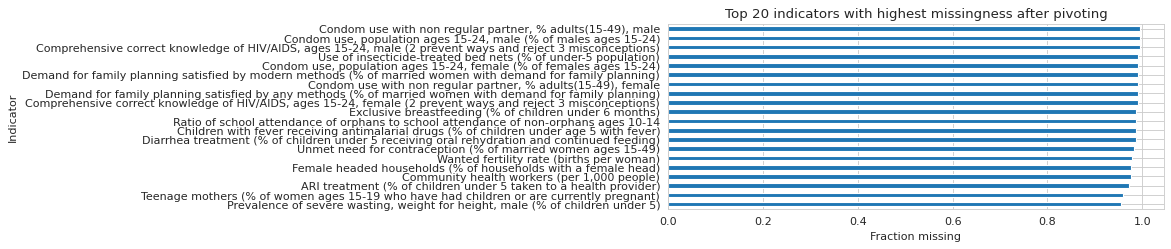

Number of candidate features before missingness filter: 312
Number of candidate features after missingness filter: 240


In [127]:
# -----------------------------
# Keep features with acceptable missingness
# -----------------------------
# After pivoting, some indicators are extremely sparse.
# We drop predictors with >40% missing values in the modeling table.

exclude_cols = ["Country Name", "Country Code", "Year", "target_life_expectancy_10y"]
feature_cols = [c for c in model_df.columns if c not in exclude_cols]

missing_frac = model_df[feature_cols].isna().mean().sort_values(ascending=False)

plt.figure(figsize=(8, 3), dpi=80)
missing_frac.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 indicators with highest missingness after pivoting")
plt.xlabel("Fraction missing")
plt.ylabel("Indicator")
plt.tight_layout()
plt.show()

feature_cols = missing_frac[missing_frac <= 0.40].index.tolist()

print("Number of candidate features before missingness filter:", len([c for c in model_df.columns if c not in exclude_cols]))
print("Number of candidate features after missingness filter:", len(feature_cols))

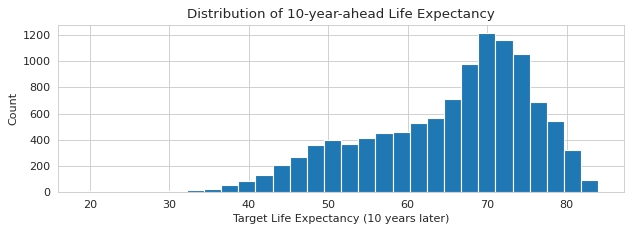

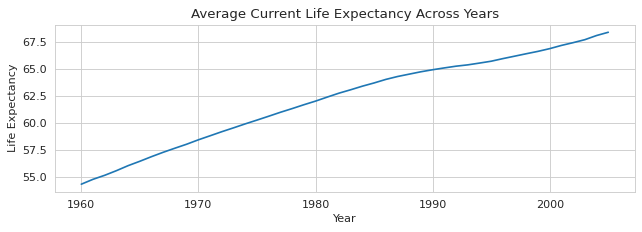

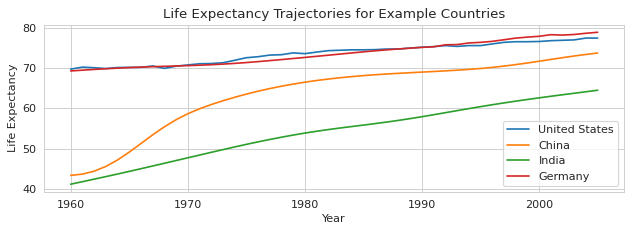

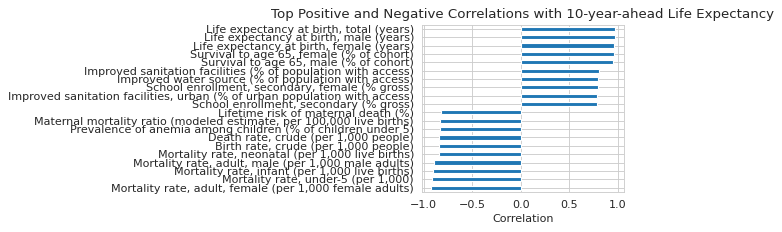

In [128]:

# -----------------------------
# Small EDA on modeling dataset
# -----------------------------
# A. Distribution of the 10-year-ahead target
plt.figure(figsize=(8, 3), dpi=80)
plt.hist(model_df["target_life_expectancy_10y"], bins=30)
plt.title("Distribution of 10-year-ahead Life Expectancy")
plt.xlabel("Target Life Expectancy (10 years later)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# B. Average life expectancy over time
avg_life_by_year = model_df.groupby("Year")[life_col].mean()

plt.figure(figsize=(8, 3), dpi=80)
plt.plot(avg_life_by_year.index, avg_life_by_year.values)
plt.title("Average Current Life Expectancy Across Years")
plt.xlabel("Year")
plt.ylabel("Life Expectancy")
plt.tight_layout()
plt.show()
plt.close()

# C. Example country trajectories
example_countries = ["United States", "China", "India", "Germany"]
plot_df = model_df[model_df["Country Name"].isin(example_countries)]

plt.figure(figsize=(8, 3), dpi=80)
for c in example_countries:
    temp_country = plot_df[plot_df["Country Name"] == c]
    if not temp_country.empty:
        plt.plot(temp_country["Year"], temp_country[life_col], label=c)

plt.title("Life Expectancy Trajectories for Example Countries")
plt.xlabel("Year")
plt.ylabel("Life Expectancy")
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

# D. Correlation with the target (top numeric predictors)
corr_df = model_df[feature_cols + ["target_life_expectancy_10y"]].corr(numeric_only=True)
target_corr = corr_df["target_life_expectancy_10y"].drop("target_life_expectancy_10y").sort_values()

top_neg = target_corr.head(10)
top_pos = target_corr.tail(10)
corr_plot = pd.concat([top_neg, top_pos])

plt.figure(figsize=(8, 3), dpi=80)
corr_plot.sort_values().plot(kind="barh")
plt.title("Top Positive and Negative Correlations with 10-year-ahead Life Expectancy")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()
plt.close()

# IV. Model And Evaluation



In [129]:
# -----------------------------
# Further packages
# -----------------------------
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [130]:

# -----------------------------
# Temporal train/test split
# -----------------------------
# train on earlier years, test on later years.
# We do it this way here as we want to be sure we can predict the future.

X = model_df[feature_cols].copy()
y = model_df["target_life_expectancy_10y"].copy()
years = model_df["Year"].copy()

unique_years = sorted(years.unique())
cutoff_year = unique_years[int(len(unique_years) * 0.8)]  # last ~20% of years used as test

train_mask = years < cutoff_year
test_mask = years >= cutoff_year

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()
y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

train_years = years.loc[train_mask]
test_years = years.loc[test_mask]

print(f"Train years: {train_years.min()} - {train_years.max()}")
print(f"Test years:  {test_years.min()} - {test_years.max()}")
print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Number of features:", X_train.shape[1])



Train years: 1960 - 1995
Test years:  1996 - 2005
Training rows: 8676
Test rows: 2410
Number of features: 240


In [131]:
# -----------------------------
# Baseline model
# -----------------------------
results = []

baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

results.append(
    evaluate_model(
        "Baseline Linear Regression",
        y_test,
        baseline_pred,
        n_features=X_train.shape[1]
    )
)

print(results)

[{'Model': 'Baseline Linear Regression', 'Num Features / Components': 240, 'RMSE': np.float64(3.3284777638136642), 'MAE': 2.186085399062725, 'R2': 0.8531593095565139}]


In [132]:
# -----------------------------
# 9. PCA approach
# -----------------------------
# We use PCA to keep 95% of variance, then run linear regression on PCs.

pca_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("model", LinearRegression())
])

pca_model.fit(X_train, y_train)
pca_pred = pca_model.predict(X_test)

n_pca_components = pca_model.named_steps["pca"].n_components_

results.append(
    evaluate_model(
        "PCA (95% variance) + Linear Regression",
        y_test,
        pca_pred,
        n_features=n_pca_components
    )
)

print("Number of PCA components retained:", n_pca_components)
print(results)



Number of PCA components retained: 35
[{'Model': 'Baseline Linear Regression', 'Num Features / Components': 240, 'RMSE': np.float64(3.3284777638136642), 'MAE': 2.186085399062725, 'R2': 0.8531593095565139}, {'Model': 'PCA (95% variance) + Linear Regression', 'Num Features / Components': np.int64(35), 'RMSE': np.float64(2.826305995796293), 'MAE': 1.8684834179802656, 'R2': 0.8941249916352203}]


In [133]:
# -----------------------------
# 10. Shared preprocessing for LASSO / Ridge
# -----------------------------
#Impute with median as strategy, standard scaling

preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_scaled = preprocess.fit_transform(X_train)
X_test_scaled = preprocess.transform(X_test)

feature_names = np.array(feature_cols)



In [134]:

# -----------------------------
# 11. LASSO feature selection
# -----------------------------
# LASSO sets some coefficients exactly to zero.
# We use non-zero coefficients as the selected features.
RANDOM_STATE=42

lasso_selector = LassoCV(
    alphas=np.logspace(-4, 1, 30),
    cv=3,
    max_iter=10000,
    random_state=RANDOM_STATE
)

lasso_selector.fit(X_train_scaled, y_train)

#We select the variables which have not been shrinked over a certain level
lasso_selected_idx = np.where(np.abs(lasso_selector.coef_) > 1e-8)[0]

# Fallback in case LASSO is too aggressive
if len(lasso_selected_idx) == 0:
    lasso_selected_idx = np.argsort(np.abs(lasso_selector.coef_))[-20:]

lasso_selected_features = feature_names[lasso_selected_idx]

print("LASSO selected feature count:", len(lasso_selected_features))
print("\nTop LASSO-selected features:")
print(pd.Series(np.abs(lasso_selector.coef_[lasso_selected_idx]), index=lasso_selected_features)
      .sort_values(ascending=False)
      .head(20))

# Fit a standard linear regression using only the LASSO-selected features
lasso_fs_model = LinearRegression()
lasso_fs_model.fit(X_train_scaled[:, lasso_selected_idx], y_train)
lasso_fs_pred = lasso_fs_model.predict(X_test_scaled[:, lasso_selected_idx])

results.append(
    evaluate_model(
        "LASSO-selected features + Linear Regression",
        y_test,
        lasso_fs_pred,
        n_features=len(lasso_selected_features)
    )
)

# Also evaluate direct LASSO regression itself
lasso_direct_pred = lasso_selector.predict(X_test_scaled)

results.append(
    evaluate_model(
        "Direct LASSO Regression",
        y_test,
        lasso_direct_pred,
        n_features=int((np.abs(lasso_selector.coef_) > 1e-8).sum())
    )
)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 167.30406247360952, tolerance: 61.048785526173276
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 123.93827492232231, tolerance: 61.048785526173276
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 515.0811505984166, tolerance: 61.048785526173276
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: Convergen

LASSO selected feature count: 26

Top LASSO-selected features:
Life expectancy at birth, total (years)                                      3.779494
Life expectancy at birth, female (years)                                     2.729914
Survival to age 65, male (% of cohort)                                       1.174094
Lifetime risk of maternal death (%)                                          1.158839
Mortality rate, under-5 (per 1,000)                                          0.460695
Labor force, female (% of total labor force)                                 0.414662
Sex ratio at birth (male births per female births)                           0.387300
Incidence of tuberculosis (per 100,000 people)                               0.345613
Improved sanitation facilities, urban (% of urban population with access)    0.287167
GNI per capita, Atlas method (current US$)                                   0.277034
Public spending on education, total (% of GDP)                               

In [135]:

# -----------------------------
# 12. Ridge-based feature ranking
# -----------------------------
# Ridge does not zero out features, but coefficient magnitude can still rank importance.
# We choose top-k ridge-ranked features using a small validation split inside the training period.

train_unique_years = sorted(train_years.unique())
val_cutoff_year = train_unique_years[int(len(train_unique_years) * 0.8)]

subtrain_mask = train_years < val_cutoff_year
val_mask = train_years >= val_cutoff_year

X_subtrain = X_train_scaled[subtrain_mask.values]
X_val = X_train_scaled[val_mask.values]
y_subtrain = y_train.loc[subtrain_mask].values
y_val = y_train.loc[val_mask].values

ridge_ranker = RidgeCV(alphas=np.logspace(-3, 3, 20), cv=3)
ridge_ranker.fit(X_subtrain, y_subtrain)

ridge_ranked_idx = np.argsort(np.abs(ridge_ranker.coef_))[::-1]

candidate_ks = [10, 20, 30, 50, 75, 100, 125, 150]
best_k = None
best_val_rmse = np.inf

for k in candidate_ks:
    idx = ridge_ranked_idx[:k]
    temp_model = LinearRegression()
    temp_model.fit(X_subtrain[:, idx], y_subtrain)
    temp_pred = temp_model.predict(X_val[:, idx])
    temp_rmse = rmse(y_val, temp_pred)

    if temp_rmse < best_val_rmse:
        best_val_rmse = temp_rmse
        best_k = k

print("Best number of ridge-ranked features from validation:", best_k)

# Refit ridge ranking on full training data
ridge_full = RidgeCV(alphas=np.logspace(-3, 3, 20), cv=3)
ridge_full.fit(X_train_scaled, y_train)

ridge_full_ranked_idx = np.argsort(np.abs(ridge_full.coef_))[::-1]
ridge_selected_idx = ridge_full_ranked_idx[:best_k]
ridge_selected_features = feature_names[ridge_selected_idx]

print("\nTop ridge-ranked features:")
print(pd.Series(np.abs(ridge_full.coef_[ridge_selected_idx]), index=ridge_selected_features)
      .sort_values(ascending=False)
      .head(20))

ridge_fs_model = LinearRegression()
ridge_fs_model.fit(X_train_scaled[:, ridge_selected_idx], y_train)
ridge_fs_pred = ridge_fs_model.predict(X_test_scaled[:, ridge_selected_idx])

results.append(
    evaluate_model(
        f"Ridge-ranked top {best_k} features + Linear Regression",
        y_test,
        ridge_fs_pred,
        n_features=best_k
    )
)

# Also evaluate direct ridge regression on all features
ridge_direct_pred = ridge_full.predict(X_test_scaled)

results.append(
    evaluate_model(
        "Direct Ridge Regression",
        y_test,
        ridge_direct_pred,
        n_features=X_train.shape[1]
    )
)


Best number of ridge-ranked features from validation: 20

Top ridge-ranked features:
Life expectancy at birth, female (years)                                     1.494922
Life expectancy at birth, total (years)                                      1.385443
Life expectancy at birth, male (years)                                       1.255508
Birth rate, crude (per 1,000 people)                                         0.694023
Incidence of tuberculosis (per 100,000 people)                               0.691904
Survival to age 65, female (% of cohort)                                     0.672824
Mortality rate, under-5 (per 1,000)                                          0.667792
Survival to age 65, male (% of cohort)                                       0.643813
Mortality rate, adult, female (per 1,000 female adults)                      0.553737
Lifetime risk of maternal death (%)                                          0.550010
GNI per capita, Atlas method (current US$)             


================ MODEL COMPARISON ================



,Model,Num Features / Components,RMSE,MAE,R2
0,Direct LASSO Regression,26,2.597210,1.746041,0.910593
1,LASSO-selected features + Linear Regression,26,2.634443,1.756889,0.908012
2,Ridge-ranked top 20 features + Linear Regression,20,2.714088,1.791964,0.902366
3,Direct Ridge Regression,240,2.749223,1.802802,0.899821
4,PCA (95% variance) + Linear Regression,35,2.826306,1.868483,0.894125
5,Baseline Linear Regression,240,3.328478,2.186085,0.853159


/tmp/ipykernel_6079/3376391476.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


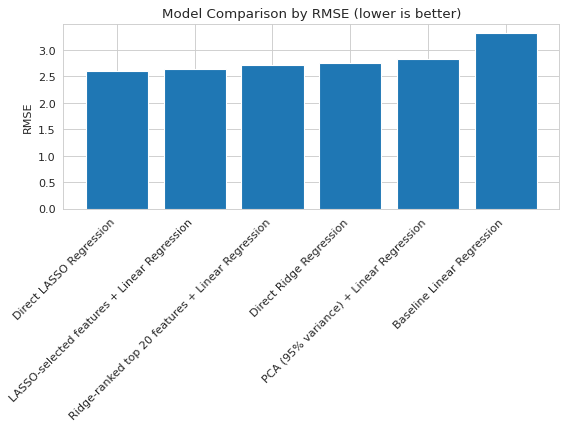

/tmp/ipykernel_6079/3376391476.py:23: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


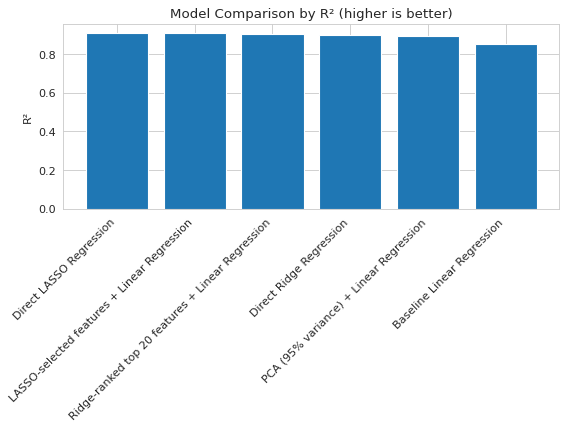

In [136]:

# -----------------------------
# 13. Compare model performance
# -----------------------------
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

print("\n================ MODEL COMPARISON ================\n")
display(results_df)

plt.figure(figsize=(8, 3), dpi=80)
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Model Comparison by RMSE (lower is better)")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(8, 3), dpi=80)
plt.bar(results_df["Model"], results_df["R2"])
plt.title("Model Comparison by R² (higher is better)")
plt.ylabel("R²")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
plt.close()

Best model based on RMSE: Direct LASSO Regression


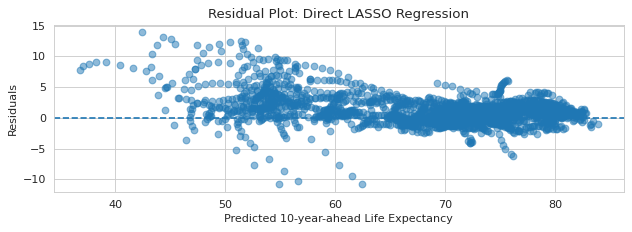

In [137]:
# -----------------------------
# 14. Residual plot for best model
# -----------------------------
best_model_name = results_df.iloc[0]["Model"]
print("Best model based on RMSE:", best_model_name)

predictions_dict = {
    "Baseline Linear Regression": baseline_pred,
    "PCA (95% variance) + Linear Regression": pca_pred,
    "LASSO-selected features + Linear Regression": lasso_fs_pred,
    "Direct LASSO Regression": lasso_direct_pred,
    f"Ridge-ranked top {best_k} features + Linear Regression": ridge_fs_pred,
    "Direct Ridge Regression": ridge_direct_pred
}

best_pred = predictions_dict[best_model_name]
residuals = y_test - best_pred

plt.figure(figsize=(8, 3), dpi=80)
plt.scatter(best_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.title(f"Residual Plot: {best_model_name}")
plt.xlabel("Predicted 10-year-ahead Life Expectancy")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()
plt.close()


In [138]:
# -----------------------------
# 15. Final summary objects for later reference
# -----------------------------
lasso_feature_importance = (
    pd.Series(lasso_selector.coef_, index=feature_names)
    .loc[lambda s: s.abs() > 1e-8]
    .sort_values(key=np.abs, ascending=False)
)

ridge_feature_importance = (
    pd.Series(ridge_full.coef_, index=feature_names)
    .sort_values(key=np.abs, ascending=False)
)

print("\nTop 15 LASSO-selected features:")
display(lasso_feature_importance.head(15))

print("\nTop 15 Ridge-ranked features:")
display(ridge_feature_importance.head(15))

print("\n Key outputs available:")
print("- model_df")
print("- results_df")
print("- lasso_feature_importance")
print("- ridge_feature_importance")
print("- lasso_selected_features")
print("- ridge_selected_features")



Top 15 LASSO-selected features:


,0
"Life expectancy at birth, total (years)",3.779494
"Life expectancy at birth, female (years)",2.729914
"Survival to age 65, male (% of cohort)",1.174094
Lifetime risk of maternal death (%),-1.158839
"Mortality rate, under-5 (per 1,000)",-0.460695
"Labor force, female (% of total labor force)",-0.414662
Sex ratio at birth (male births per female births),0.387300
"Incidence of tuberculosis (per 100,000 people)",-0.345613
"Improved sanitation facilities, urban (% of urban population with access)",0.287167
"GNI per capita, Atlas method (current US$)",0.277034



Top 15 Ridge-ranked features:


,0
"Life expectancy at birth, female (years)",1.494922
"Life expectancy at birth, total (years)",1.385443
"Life expectancy at birth, male (years)",1.255508
"Birth rate, crude (per 1,000 people)",-0.694023
"Incidence of tuberculosis (per 100,000 people)",-0.691904
"Survival to age 65, female (% of cohort)",0.672824
"Mortality rate, under-5 (per 1,000)",-0.667792
"Survival to age 65, male (% of cohort)",0.643813
"Mortality rate, adult, female (per 1,000 female adults)",-0.553737
Lifetime risk of maternal death (%),-0.550010



 Key outputs available:
- model_df
- results_df
- lasso_feature_importance
- ridge_feature_importance
- lasso_selected_features
- ridge_selected_features


In [139]:

# ============================================================
# ADDITIONAL NONLINEAR MODELS IF WISHED TO GO MORE COMPLICATED
# ============================================================

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# We reuse some of the stuff available above, including
# X_train, X_test, y_train, y_test
# preprocess
# feature_names
# results_df
# evaluate_model
# rmse

# ------------------------------------------------------------
# Preprocess once for tree-based models
# ------------------------------------------------------------
# Trees need no scaling, but they do need missing values handled!
# Hence we only impute here

tree_imputer = SimpleImputer(strategy="median")

X_train_tree = tree_imputer.fit_transform(X_train)
X_test_tree = tree_imputer.transform(X_test)

print("Tree-model training matrix shape:", X_train_tree.shape)
print("Tree-model test matrix shape:", X_test_tree.shape)



Tree-model training matrix shape: (8676, 240)
Tree-model test matrix shape: (2410, 240)


In [140]:

# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train_tree, y_train)
rf_pred = rf_model.predict(X_test_tree)

rf_result = evaluate_model(
    "Random Forest Regressor",
    y_test,
    rf_pred,
    n_features=X_train.shape[1]
)

print("Random Forest performance:")
print(rf_result)


Random Forest performance:
{'Model': 'Random Forest Regressor', 'Num Features / Components': 240, 'RMSE': np.float64(2.4273799548917827), 'MAE': 1.7316983056147968, 'R2': 0.9219036708943806}


In [141]:

# ------------------------------------------------------------
# Gradient Boosting
# ------------------------------------------------------------
gbr_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=RANDOM_STATE
)

gbr_model.fit(X_train_tree, y_train)
gbr_pred = gbr_model.predict(X_test_tree)

gbr_result = evaluate_model(
    "Gradient Boosting Regressor",
    y_test,
    gbr_pred,
    n_features=X_train.shape[1]
)

print("\nGradient Boosting performance:")
print(gbr_result)



Gradient Boosting performance:
{'Model': 'Gradient Boosting Regressor', 'Num Features / Components': 240, 'RMSE': np.float64(2.782128412088074), 'MAE': 1.7644148893329343, 'R2': 0.8974089580088506}


In [142]:

# ------------------------------------------------------------
# Add tree models to the comparison table
# ------------------------------------------------------------
tree_results_df = pd.DataFrame([rf_result, gbr_result])

results_df_extended = pd.concat(
    [results_df, tree_results_df],
    axis=0,
    ignore_index=True
).sort_values("RMSE").reset_index(drop=True)

print("\n================ EXTENDED MODEL COMPARISON ================\n")
display(results_df_extended)


================ EXTENDED MODEL COMPARISON ================



,Model,Num Features / Components,RMSE,MAE,R2
0,Random Forest Regressor,240,2.427380,1.731698,0.921904
1,Direct LASSO Regression,26,2.597210,1.746041,0.910593
2,LASSO-selected features + Linear Regression,26,2.634443,1.756889,0.908012
3,Ridge-ranked top 20 features + Linear Regression,20,2.714088,1.791964,0.902366
4,Direct Ridge Regression,240,2.749223,1.802802,0.899821
5,Gradient Boosting Regressor,240,2.782128,1.764415,0.897409
6,PCA (95% variance) + Linear Regression,35,2.826306,1.868483,0.894125
7,Baseline Linear Regression,240,3.328478,2.186085,0.853159


/tmp/ipykernel_6079/2410926156.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


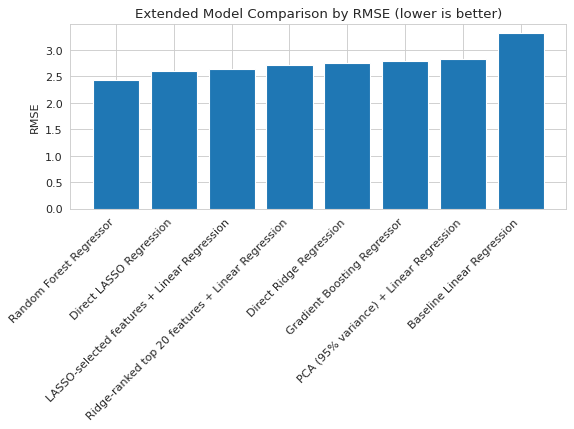

/tmp/ipykernel_6079/2410926156.py:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


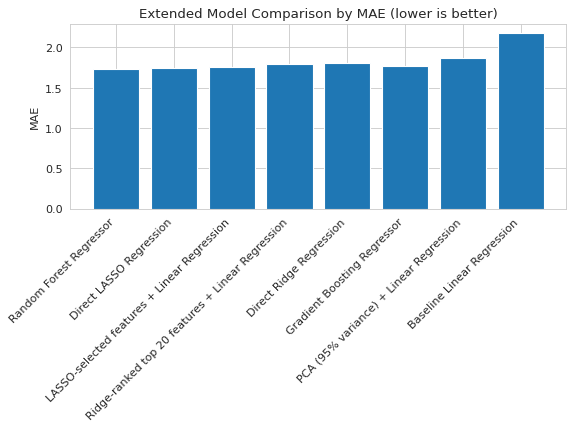

/tmp/ipykernel_6079/2410926156.py:27: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


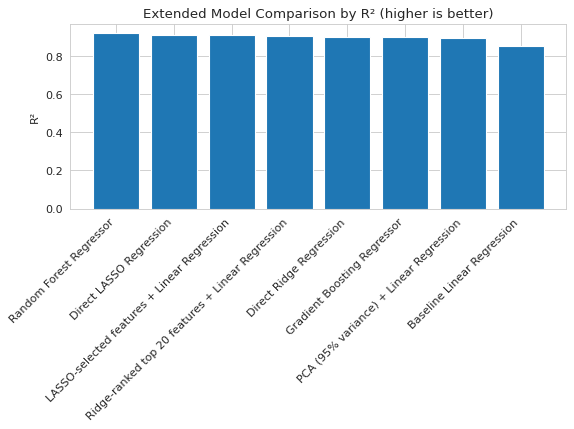

In [143]:

# ------------------------------------------------------------
# Updated comparison plots
# ------------------------------------------------------------
plt.figure(figsize=(8, 3), dpi=80)
plt.bar(results_df_extended["Model"], results_df_extended["RMSE"])
plt.title("Extended Model Comparison by RMSE (lower is better)")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(8, 3), dpi=80)
plt.bar(results_df_extended["Model"], results_df_extended["MAE"])
plt.title("Extended Model Comparison by MAE (lower is better)")
plt.ylabel("MAE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(8, 3), dpi=80)
plt.bar(results_df_extended["Model"], results_df_extended["R2"])
plt.title("Extended Model Comparison by R² (higher is better)")
plt.ylabel("R²")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
plt.close()



Top 15 Random Forest important features:


,0
"Life expectancy at birth, total (years)",0.081463
"Life expectancy at birth, male (years)",0.056643
"Survival to age 65, female (% of cohort)",0.056054
"Death rate, crude (per 1,000 people)",0.054414
"Mortality rate, adult, female (per 1,000 female adults)",0.054400
"Life expectancy at birth, female (years)",0.054157
"Survival to age 65, male (% of cohort)",0.051567
"Mortality rate, under-5 (per 1,000)",0.044183
Lifetime risk of maternal death (%),0.040387
Lifetime risk of maternal death (1 in: rate varies by country),0.040252



Top 15 Gradient Boosting important features:


,0
"Survival to age 65, female (% of cohort)",0.239862
"Mortality rate, adult, female (per 1,000 female adults)",0.166224
"Life expectancy at birth, total (years)",0.156855
"Life expectancy at birth, male (years)",0.137174
"Life expectancy at birth, female (years)",0.115261
Lifetime risk of maternal death (%),0.073217
"Mortality rate, under-5 (per 1,000)",0.024617
Lifetime risk of maternal death (1 in: rate varies by country),0.013831
"Mortality rate, adult, male (per 1,000 male adults)",0.007964
"Death rate, crude (per 1,000 people)",0.007909


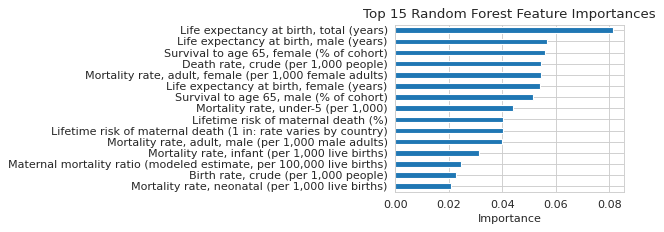

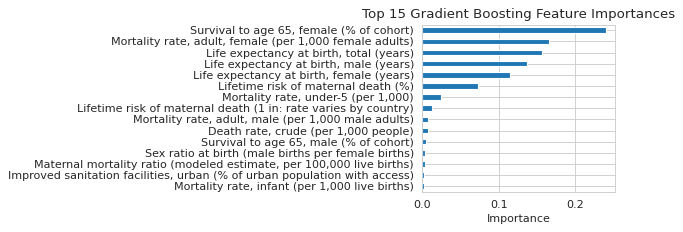

In [144]:

# ------------------------------------------------------------
# Tree-based feature importance
# ------------------------------------------------------------
rf_feature_importance = (
    pd.Series(rf_model.feature_importances_, index=feature_names)
    .sort_values(ascending=False)
)

gbr_feature_importance = (
    pd.Series(gbr_model.feature_importances_, index=feature_names)
    .sort_values(ascending=False)
)

print("\nTop 15 Random Forest important features:")
display(rf_feature_importance.head(15))

print("\nTop 15 Gradient Boosting important features:")
display(gbr_feature_importance.head(15))


# Plot top feature importances
plt.figure(figsize=(8, 3), dpi=80)
rf_feature_importance.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3), dpi=80)
gbr_feature_importance.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Gradient Boosting Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [145]:

# ------------------------------------------------------------
# Collect all predictions in one place
# ------------------------------------------------------------
all_predictions = predictions_dict.copy()
all_predictions["Random Forest Regressor"] = rf_pred
all_predictions["Gradient Boosting Regressor"] = gbr_pred

best_extended_model_name = results_df_extended.iloc[0]["Model"]
best_extended_pred = all_predictions[best_extended_model_name]

print("Best overall model after adding nonlinear methods:", best_extended_model_name)

Best overall model after adding nonlinear methods: Random Forest Regressor


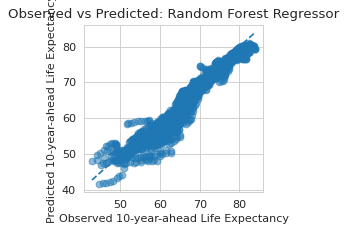

In [146]:

# ------------------------------------------------------------
# Observed vs predicted plot for best overall model
# ------------------------------------------------------------
plt.figure(figsize=(3, 3),  dpi=80)
plt.scatter(y_test, best_extended_pred, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.title(f"Observed vs Predicted: {best_extended_model_name}")
plt.xlabel("Observed 10-year-ahead Life Expectancy")
plt.ylabel("Predicted 10-year-ahead Life Expectancy")
plt.tight_layout()
plt.show()



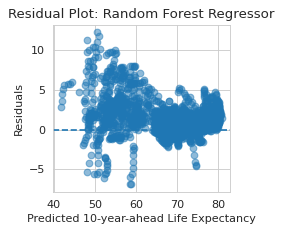

In [147]:

# ------------------------------------------------------------
# Residual plot for best overall model
# ------------------------------------------------------------
best_extended_residuals = y_test - best_extended_pred

plt.figure(figsize=(3, 3), dpi=80)
plt.scatter(best_extended_pred, best_extended_residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.title(f"Residual Plot: {best_extended_model_name}")
plt.xlabel("Predicted 10-year-ahead Life Expectancy")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()


In [148]:
# ------------------------------------------------------------
# Final objects for report
# ------------------------------------------------------------
print("- results_df_extended")
print("- rf_feature_importance")
print("- gbr_feature_importance")
print("- all_predictions")
print("- best_extended_model_name")

- results_df_extended
- rf_feature_importance
- gbr_feature_importance
- all_predictions
- best_extended_model_name


# V. Conclusion